# 33 — Pointing Game bajo protocolo único + auditoría geométrica del ROI


## Objetivo
Medir con un único protocolo —mismos *transforms* (los de `CBISROIDataset`), misma máscara y misma función `evaluate_pointing_game`— el EBPG continuo (sin umbral) de tres brazos sobre las 368 mamografías con máscara: Grad-CAM clásico del baseline, Grad-CAM clásico del extractor robusto y el mapa de la fórmula ($\psi_{\text{KAN}}$). El resultado se compara con el nulo por área de tejido (1,53 %). El cuaderno contiene: (1) la auditoría geométrica del cargador ROI, (2) el *benchmark* 368×3 y (3) la estadística y la tabla del Cap. 4. El operador focal y los controles de azar adicionales están en `scripts/control_azar_focal.py` y `scripts/formula_vs_gradcam_wsss.py`.

In [1]:
import os
import sys
import json
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

CODIGOS = os.environ.get("TESIS_CODIGOS") or os.path.abspath(os.path.join(os.getcwd(), ".."))   # raiz del repo (ejecutar desde pipeline/)
sys.path.insert(0, CODIGOS)
os.environ.setdefault("TESIS_CODIGOS", CODIGOS)
REPORTS_DIR = os.path.join(CODIGOS, "reports", "experiments")
FIGS_DIR = os.path.join(CODIGOS, "reports", "figures")
SEED = 42
print("setup OK:", os.path.isdir(REPORTS_DIR))

setup OK: True


## 1. Auditoría geométrica del cargador ROI
Pregunta: ¿las máscaras están alineadas con las imágenes tras el cambio de tamaño? (Trampa clásica de CBIS-DDSM: recortes frente a máscaras de tamaño completo.)


In [2]:
from PIL import Image
from src.data.roi_loader import get_roi_manifest, CBISROIDataset

df = get_roi_manifest()
print(f"casos ROI: {len(df)}  pacientes: {df['patient_id'].nunique()}")
sizes = [(Image.open(r['image_path']).size, Image.open(r['roi_path']).size) for _, r in df.head(400).iterrows()]
mismatch = [s for s in sizes if s[0] != s[1]]
print(f"pares tamano img==roi: {len(sizes) - len(mismatch)}/{len(sizes)}")
ds = CBISROIDataset(df)
it = ds[2]
gt = (np.asarray(it['mask_np']) > 0.5)
ys, xs = np.where(gt)
print(f"idx2 {it['patient_id']}: mask {np.asarray(it['mask_np']).shape}, fraccion {gt.mean():.4f}, "
      f"bbox rows {ys.min()}-{ys.max()} cols {xs.min()}-{xs.max()}")
audit = {"n": int(len(df)), "mismatch_tamano": int(len(mismatch)),
         "idx2_bbox": [int(ys.min()), int(ys.max()), int(xs.min()), int(xs.max())]}
json.dump(audit, open(os.path.join(REPORTS_DIR, "33_roi_audit.json"), "w"), indent=2)
print("auditoría guardada: 33_roi_audit.json")

casos ROI: 368  pacientes: 212
pares tamano img==roi: 355/368


idx2 P_00202: mask (224, 224), fraccion 0.0041, bbox rows 108-121 cols 114-136
auditoría guardada: 33_roi_audit.json


checkpoint: epoch 14, best_auc 0.7666804245840331


galería: 33_roi_alignment_gallery.png


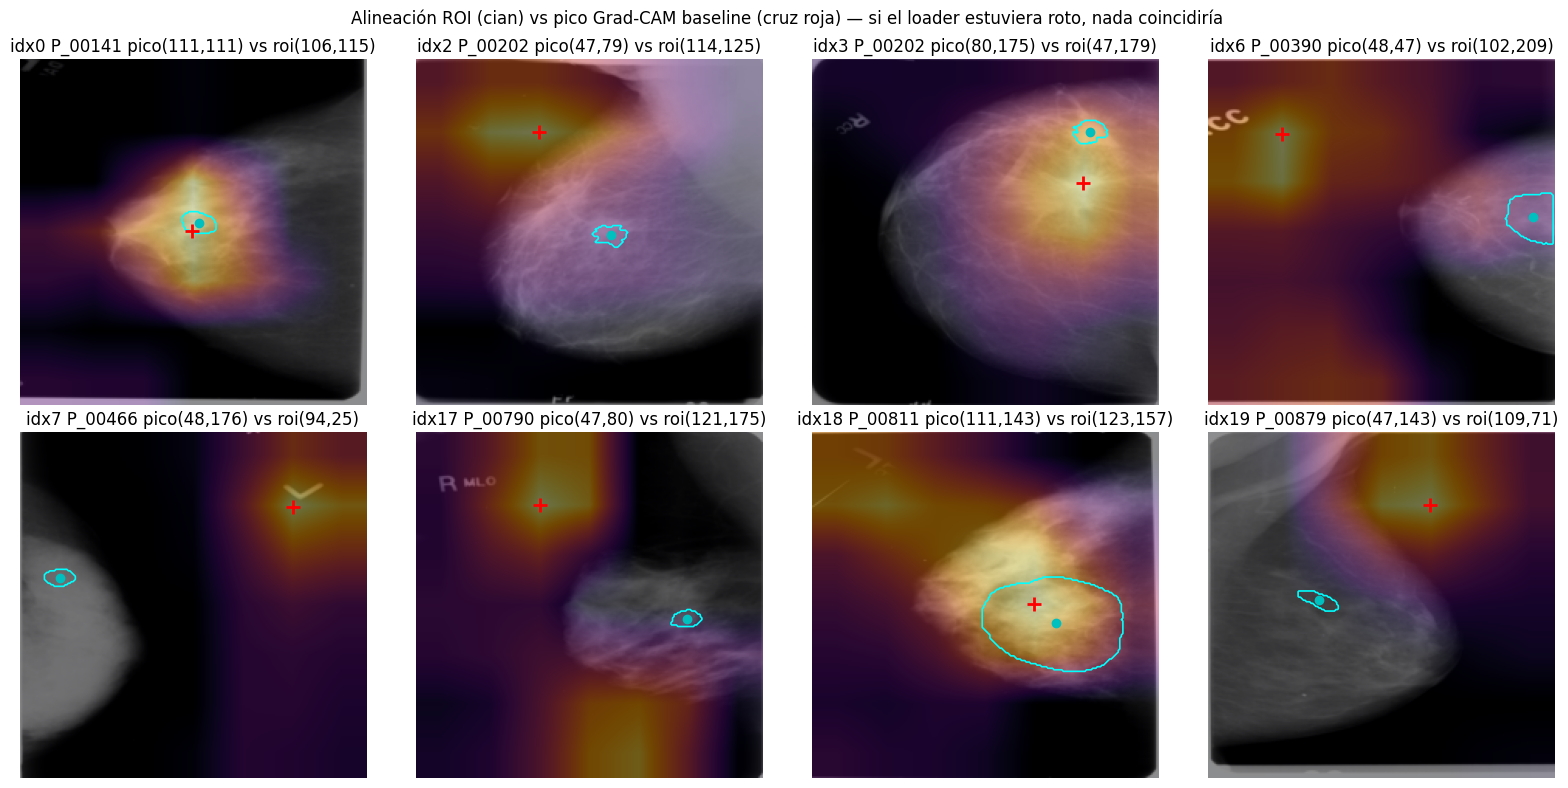

In [3]:
import torch
from torchvision import models
import torch.nn as nn
from src.explainability.pca_attribution import compute_gradcam_baseline

GAL_IDX = [0, 2, 3, 6, 7, 17, 18, 19]
m = models.resnet18(weights=None); m.fc = nn.Linear(512, 2)
ck = torch.load(os.path.join(CODIGOS, "reports", "models", "resnet18_baseline_v2.pt"),
                 map_location="cpu", weights_only=False)
m.load_state_dict(ck["model_state_dict"]); m = m.eval()
print(f"checkpoint: epoch {ck.get('epoch')}, best_auc {ck.get('best_auc')}")

fig, axes = plt.subplots(2, 4, figsize=(16, 8))
for ax, i in zip(axes.ravel(), GAL_IDX):
    it = ds[int(i)]
    img4 = it["image_tensor"].unsqueeze(0)
    gc = compute_gradcam_baseline(m, img4, target_class=1, device="cpu")
    py, px = np.unravel_index(np.argmax(gc), gc.shape)
    gt = (np.asarray(it["mask_np"]) > 0.5)
    gy, gx = (np.where(gt)[0].mean(), np.where(gt)[1].mean()) if gt.sum() else (np.nan, np.nan)
    disp = (it["image_tensor"].numpy().transpose(1, 2, 0) * np.array([0.229, 0.224, 0.225])
            + np.array([0.485, 0.456, 0.406])).clip(0, 1)
    ax.imshow(disp, cmap="gray"); ax.imshow(gc, alpha=0.45, cmap="inferno")
    ax.contour(gt, levels=[0.5], colors=["cyan"], linewidths=1.2)
    ax.plot(px, py, "r+", ms=10, mew=2); ax.plot(gx, gy, "co", ms=6)
    ax.set_title(f"idx{i} {it['patient_id']} pico({py},{px}) vs roi({gy:.0f},{gx:.0f})")
    ax.axis("off")
fig.suptitle("Alineación ROI (cian) vs pico Grad-CAM baseline (cruz roja) — si el loader estuviera roto, nada coincidiría")
fig.tight_layout(); fig.savefig(os.path.join(FIGS_DIR, "33_roi_alignment_gallery.png"), dpi=150)
print("galería: 33_roi_alignment_gallery.png")

## 2. Benchmark único 368×3
Mismo protocolo para los tres brazos. Guardado incremental por si se interrumpe.

In [5]:
import torch.nn.functional as F
from src.reporting.clinical_evidence_extractor import ClinicalEvidenceExtractor

DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
print("device:", DEVICE)
ex = ClinicalEvidenceExtractor(device=DEVICE)
print("kan64:", ex.kan64 is not None)
m_rob = ex.model
OUT_CSV = os.path.join(REPORTS_DIR, "33_pointing_unified.csv")

import csv as _csv
done = set()
if os.path.exists(OUT_CSV):
    done = {int(r["idx"]) for r in _csv.DictReader(open(OUT_CSV, encoding="utf-8"))}
    print(f"retomando: {len(done)} casos ya hechos")

mode = "a" if done else "w"
with open(OUT_CSV, mode, newline="", encoding="utf-8") as f:
    w = _csv.DictWriter(f, fieldnames=["idx", "patient_id", "pathology",
        "gc_base_ebpg", "gc_base_hit", "gc_rob_ebpg", "gc_rob_hit",
        "psi_ebpg", "psi_hit", "psi_agree_pred"])
    if not done:
        w.writeheader()
    for i in range(len(ds)):
        if i in done:
            continue
        try:
            it = ds[i]
            gt = (np.asarray(it["mask_np"]) > 0.5).astype(np.float32)
            img4 = it["image_tensor"].unsqueeze(0).to(DEVICE)
            gb = compute_gradcam_baseline(m.to(DEVICE), img4, target_class=1, device=DEVICE)
            gr = compute_gradcam_baseline(m_rob, img4, target_class=1, device=DEVICE)
            ev = ex.extract_evidence(it, df.iloc[i]["rel_img_path"])
            psi = np.asarray(ev.get("psi_kan_map"), dtype=np.float32)
            pn = (psi - psi.min()) / (psi.max() - psi.min() + 1e-8)
            a = evaluate_pointing_game(gb.astype(np.float32), gt)
            b = evaluate_pointing_game(gr.astype(np.float32), gt)
            c = evaluate_pointing_game(pn, gt)
            w.writerow({"idx": i, "patient_id": it["patient_id"], "pathology": it["pathology"],
                "gc_base_ebpg": round(a["ebpg"], 5), "gc_base_hit": a["hit"],
                "gc_rob_ebpg": round(b["ebpg"], 5), "gc_rob_hit": b["hit"],
                "psi_ebpg": round(c["ebpg"], 5), "psi_hit": c["hit"],
                "psi_agree_pred": bool(ev.get("psi_kan_agrees"))})
            f.flush()
        except Exception as e:
            w.writerow({"idx": i, "patient_id": "ERR", "pathology": "ERR",
                "gc_base_ebpg": -1, "gc_base_hit": -1, "gc_rob_ebpg": -1, "gc_rob_hit": -1,
                "psi_ebpg": -1, "psi_hit": -1, "psi_agree_pred": False})
            print(f"idx{i} ERROR: {e}")
        if (i + 1) % 50 == 0:
            print(f"  {i+1}/{len(ds)}", flush=True)
print("benchmark guardado:", OUT_CSV)

device: cuda


kan64: True


  50/368


  100/368


  150/368


  200/368


  250/368


  300/368


  350/368


benchmark guardado: <repo>\reports\experiments\33_pointing_unified.csv


## 3. Estadística y tabla
Medias con IC95 % bootstrap, comparaciones pareadas de Wilcoxon entre brazos y referencia del nulo por área de tejido (el tumor ocupa en promedio el 1,53 % del tejido).

{
 "gc_base": {
  "ebpg_global": 0.0085,
  "ci95": [
   0.0069,
   0.0103
  ],
  "hit_global": 0.0598,
  "ebpg_mal": 0.0128,
  "hit_mal": 0.0968,
  "n": 368,
  "n_mal": 155
 },
 "gc_rob": {
  "ebpg_global": 0.0085,
  "ci95": [
   0.007,
   0.01
  ],
  "hit_global": 0.0163,
  "ebpg_mal": 0.0122,
  "hit_mal": 0.0387,
  "n": 368,
  "n_mal": 155
 },
 "psi": {
  "ebpg_global": 0.0112,
  "ci95": [
   0.0093,
   0.0135
  ],
  "hit_global": 0.0245,
  "ebpg_mal": 0.0151,
  "hit_mal": 0.0452,
  "n": 368,
  "n_mal": 155
 },
 "psi_agree_pred": 0.2962,
 "wilcoxon_gcrob_vs_gcbase": 0.21208147353562312,
 "wilcoxon_psi_vs_gcrob": 2.83152049806775e-09
}


stats: 33_pointing_stats.json | figura: 33_pointing_unified.png


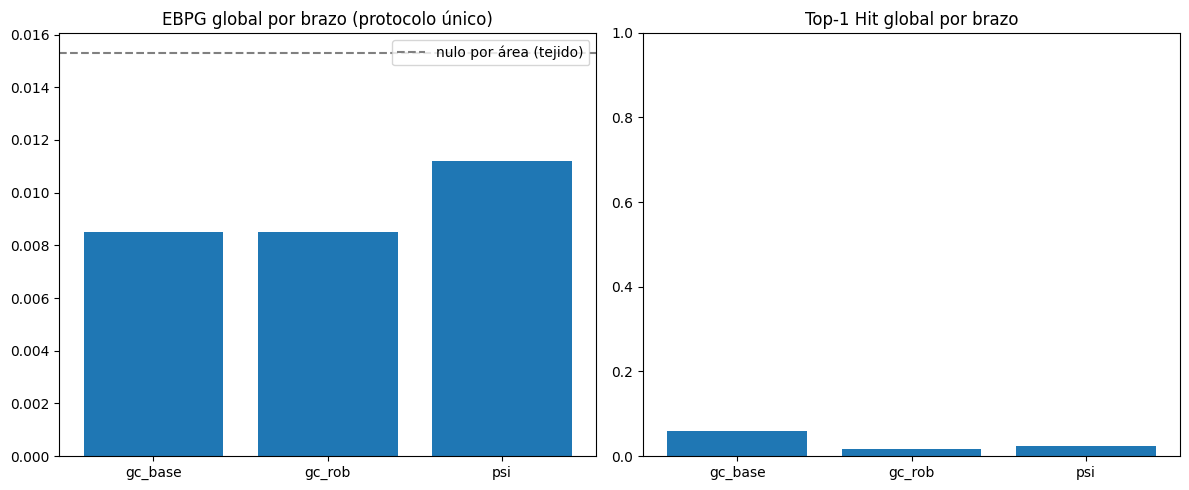

In [6]:
from scipy.stats import wilcoxon

d = pd.read_csv(os.path.join(REPORTS_DIR, "33_pointing_unified.csv"))
d = d[d["patient_id"] != "ERR"].copy()
mal = d[d["pathology"].str.upper() == "MALIGNANT"]
rng = np.random.default_rng(SEED)

def boot_ci(v, B=2000):
    v = np.asarray(v, dtype=float)
    bs = [rng.choice(v, size=len(v), replace=True).mean() for _ in range(B)]
    return float(np.percentile(bs, 2.5)), float(np.percentile(bs, 97.5))

stats = {}
for arm in ["gc_base", "gc_rob", "psi"]:
    e, h = d[f"{arm}_ebpg"].values, d[f"{arm}_hit"].values
    em, hm = mal[f"{arm}_ebpg"].values, mal[f"{arm}_hit"].values
    lo, hi = boot_ci(e)
    stats[arm] = {"ebpg_global": round(float(e.mean()), 4), "ci95": [round(lo, 4), round(hi, 4)],
        "hit_global": round(float(h.mean()), 4), "ebpg_mal": round(float(em.mean()), 4),
        "hit_mal": round(float(hm.mean()), 4), "n": int(len(d)), "n_mal": int(len(mal))}
stats["psi_agree_pred"] = round(float(d["psi_agree_pred"].mean()), 4)
try:
    stats["wilcoxon_gcrob_vs_gcbase"] = float(wilcoxon(d["gc_rob_ebpg"], d["gc_base_ebpg"], alternative="two-sided").pvalue)
    stats["wilcoxon_psi_vs_gcrob"] = float(wilcoxon(d["psi_ebpg"], d["gc_rob_ebpg"], alternative="two-sided").pvalue)
except Exception as e:
    stats["wilcoxon_error"] = str(e)
print(json.dumps(stats, indent=1))
json.dump(stats, open(os.path.join(REPORTS_DIR, "33_pointing_stats.json"), "w"), indent=2)

fig, axes = plt.subplots(1, 2, figsize=(12, 5))
arms = ["gc_base", "gc_rob", "psi"]
axes[0].bar(arms, [stats[a]["ebpg_global"] for a in arms])
axes[0].axhline(0.0153, color="gray", ls="--", label="nulo por área (tejido)")
axes[0].set_title("EBPG global por brazo (protocolo único)"); axes[0].legend()
axes[1].bar(arms, [stats[a]["hit_global"] for a in arms])
axes[1].set_title("Top-1 Hit global por brazo"); axes[1].set_ylim(0, 1)
fig.tight_layout(); fig.savefig(os.path.join(FIGS_DIR, "33_pointing_unified.png"), dpi=150)
print("stats: 33_pointing_stats.json | figura: 33_pointing_unified.png")

In [7]:
s = json.load(open(os.path.join(REPORTS_DIR, "33_pointing_stats.json"), encoding="utf-8"))
rows = []
for arm, label in [("gc_base", "Grad-CAM clásico baseline"), ("gc_rob", "Grad-CAM clásico robusto"),
                      ("psi", "psi\\_KAN (fórmula R3)")]:
    v = s[arm]
    rows.append(f"{label} & {v['ebpg_global']:.4f} & {v['hit_global']:.4f} & {v['ebpg_mal']:.4f} & {v['hit_mal']:.4f} \\\\\n")
tex = ("\\begin{table}[htbp]\n\\centering\n\\small\n"
       "\\caption{Pointing Game bajo protocolo único 224 (NB33, $N=368$). "
       "Acuerdo pico psi\\_KAN vs WSSS: " + f"{s.get('psi_agree_pred', float('nan')):.3f}" + ".}\n"
       "\\label{tab:pointing_unified}\n\\begin{tabular}{lcccc}\n\\toprule\n"
       "Brazo & EBPG glob. & Hit glob. & EBPG mal. & Hit mal. \\\\ \\midrule\n"
       + "".join(rows) + "\\bottomrule\n\\end{tabular}\n\\end{table}\n")
open(os.path.join(REPORTS_DIR, "tab_pointing_unified.tex"), "w", encoding="utf-8").write(tex)
print("tabla: tab_pointing_unified.tex")

tabla: tab_pointing_unified.tex


## Cierre
Sin umbral, ningún brazo supera el nulo por área de tejido (1,53 %): EBPG global de 0,85 % (Grad-CAM del baseline y del robusto) y de 1,12 % (fórmula); en lesiones malignas, 1,28 %, 1,22 % y 1,51 %. Los valores proceden de `reports/experiments/33_pointing_stats.json`.